# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 01: Dataset Exploration

### Objective

This notebook performs an initial exploration of the raw iris datasets before any preprocessing.

The objectives are:

1. Load the CASIA-Iris-Thousand dataset.
2. Load the IIT Delhi Iris dataset.
3. Count the total number of iris images.
4. Determine the number of identities.
5. Determine the number of samples available for each identity.
6. Analyze image resolutions.
7. Analyze left/right iris distribution.
8. Visualize representative iris images.
9. Analyze class imbalance.
10. Record known sensor and acquisition information.
11. Generate dataset-level statistics for later experiments.

### Important

No image preprocessing, segmentation, normalization, enhancement, or augmentation is performed in this notebook.

This notebook only investigates the raw datasets and establishes the baseline data inventory.

## 1. Import Required Libraries

The following libraries are used for:

- filesystem traversal
- image loading
- numerical computation
- tabular analysis
- visualization
- saving statistical reports

In [1]:
# Core Python libraries
from pathlib import Path
import os
import re
import json
import random
import warnings

# Numerical and data handling
import numpy as np
import pandas as pd

# Image processing
from PIL import Image, ExifTags

# Visualization
import matplotlib.pyplot as plt

# Display utilities
from IPython.display import display

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Define Project Paths

The notebook is located inside:

`LargeScale_Synthetic_Iris_Generation/notebooks/`

Therefore, the project root is one directory above the notebook directory.

The raw datasets are expected at:

- `datasets/raw/CASIA-Iris-Thousand`
- `datasets/raw/IITD`

The generated analysis results will be stored in:

- `results/dataset_exploration/`

This keeps raw data separate from generated outputs.

In [2]:
# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()

# Detect project root robustly
if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. "
        "Please run this notebook from the project directory "
        "or its notebooks directory."
    )

RAW_DATA_DIR = PROJECT_ROOT / "datasets" / "raw"

CASIA_DIR = RAW_DATA_DIR / "CASIA-Iris-Thousand"
IITD_DIR = RAW_DATA_DIR / "IITD"

RESULTS_DIR = PROJECT_ROOT / "results" / "dataset_exploration"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:")
print(PROJECT_ROOT)

print("\nRaw dataset directory:")
print(RAW_DATA_DIR)

print("\nCASIA directory exists:", CASIA_DIR.exists())
print("IITD directory exists:", IITD_DIR.exists())

print("\nResults directory:")
print(RESULTS_DIR)

Project root:
E:\Research\LargeScale_Synthetic_Iris_Generation

Raw dataset directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\datasets\raw

CASIA directory exists: True
IITD directory exists: True

Results directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration


## 3. Verify Dataset Directories

Before processing thousands of images, verify that the expected directories exist and inspect their contents.

This prevents path errors later in the project.

In [3]:
def inspect_directory(directory, max_items=20):
    """
    Display a compact view of a directory.
    """
    directory = Path(directory)

    if not directory.exists():
        print(f"Directory does not exist: {directory}")
        return

    items = sorted(directory.iterdir())

    print(f"\nDirectory: {directory}")
    print(f"Number of direct children: {len(items)}")

    for item in items[:max_items]:
        item_type = "DIR " if item.is_dir() else "FILE"
        print(f"[{item_type}] {item.name}")

    if len(items) > max_items:
        print(f"... and {len(items) - max_items} more items")


inspect_directory(CASIA_DIR)
inspect_directory(IITD_DIR)


Directory: E:\Research\LargeScale_Synthetic_Iris_Generation\datasets\raw\CASIA-Iris-Thousand
Number of direct children: 2
[DIR ] CASIA-Iris-Thousand
[FILE] iris_thousands.csv

Directory: E:\Research\LargeScale_Synthetic_Iris_Generation\datasets\raw\IITD
Number of direct children: 219
[DIR ] .ipynb_checkpoints
[DIR ] 001
[DIR ] 002
[DIR ] 003
[DIR ] 004
[DIR ] 005
[DIR ] 006
[DIR ] 007
[DIR ] 008
[DIR ] 009
[DIR ] 010
[DIR ] 011
[DIR ] 012
[DIR ] 013
[DIR ] 014
[DIR ] 015
[DIR ] 016
[DIR ] 017
[DIR ] 018
[DIR ] 019
... and 199 more items


## 4. Supported Image Formats

The raw datasets may contain images in formats such as:

- JPG / JPEG
- PNG
- BMP
- TIFF

The following function identifies all supported image files recursively.

In [4]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}


def get_image_files(directory):
    """
    Recursively find all supported image files.
    """
    directory = Path(directory)

    if not directory.exists():
        return []

    image_files = [
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    return sorted(image_files)


casia_files = get_image_files(CASIA_DIR)
iitd_files = get_image_files(IITD_DIR)

print("CASIA image count:", len(casia_files))
print("IITD image count:", len(iitd_files))

CASIA image count: 20000
IITD image count: 2180


## 5. Basic Dataset Inventory

At this stage we determine:

- total images
- file extensions
- folder depth
- first and last few image paths

This gives us a first understanding of how each dataset is organized.

In [5]:
def basic_inventory(image_files):
    """
    Generate basic inventory information for a collection of image paths.
    """
    extensions = pd.Series(
        [path.suffix.lower() for path in image_files],
        name="extension"
    )

    return {
        "total_images": len(image_files),
        "unique_extensions": sorted(extensions.unique().tolist()),
        "extension_distribution": extensions.value_counts().to_dict()
    }


casia_inventory = basic_inventory(casia_files)
iitd_inventory = basic_inventory(iitd_files)

print("CASIA inventory:")
print(casia_inventory)

print("\nIITD inventory:")
print(iitd_inventory)

CASIA inventory:
{'total_images': 20000, 'unique_extensions': ['.jpg'], 'extension_distribution': {'.jpg': 20000}}

IITD inventory:
{'total_images': 2180, 'unique_extensions': ['.bmp'], 'extension_distribution': {'.bmp': 2180}}


## 6. Inspect File Naming and Folder Structure

Iris datasets often encode useful information in their directory structure or filenames.

For example, CASIA-Iris-Thousand follows a subject/eye/image organization in which the directory and filename encode the subject and eye side. Therefore, we will inspect actual paths rather than assuming a particular naming convention. :contentReference[oaicite:1]{index=1}

The next cell prints representative paths from both datasets.

In [6]:
print("CASIA sample paths:\n")

for path in casia_files[:15]:
    print(path.relative_to(CASIA_DIR))

print("\n" + "=" * 70)

print("IITD sample paths:\n")

for path in iitd_files[:15]:
    print(path.relative_to(IITD_DIR))

CASIA sample paths:

CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L00.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L01.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L02.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L03.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L04.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L05.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L06.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L07.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L08.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\S5000L09.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R\S5000R00.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R\S5000R01.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R\S5000R02.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R\S5000R03.jpg
CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\R\S5000R04.jpg

IITD sample paths:

001\01_L.bmp
001\02_L.bmp
001\03_L.bmp
001\04_L.bmp
001\05_L.bmp
001\06_R

## 7. Build a Raw Image Metadata Table

For every image we record:

- dataset
- filename
- full path
- relative path
- file extension
- width
- height
- number of channels
- file size

This table will become the central metadata table for the rest of this notebook.

No image pixels are modified.

In [7]:
def inspect_image(path):
    """
    Read basic image metadata without modifying the image.
    """
    path = Path(path)

    try:
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode

            # Infer number of channels from image mode
            channel_map = {
                "1": 1,
                "L": 1,
                "LA": 2,
                "P": 1,
                "RGB": 3,
                "RGBA": 4,
                "CMYK": 4,
                "YCbCr": 3,
                "I": 1,
                "F": 1
            }

            channels = channel_map.get(mode, None)

            return {
                "width": width,
                "height": height,
                "mode": mode,
                "channels": channels,
                "file_size_bytes": path.stat().st_size
            }

    except Exception as e:
        return {
            "width": None,
            "height": None,
            "mode": None,
            "channels": None,
            "file_size_bytes": path.stat().st_size if path.exists() else None
        }


def build_metadata_table(image_files, dataset_name, dataset_root):

    records = []

    for path in image_files:

        image_info = inspect_image(path)

        records.append({
            "dataset": dataset_name,
            "filename": path.name,
            "relative_path": str(path.relative_to(dataset_root)),
            "full_path": str(path.resolve()),
            "extension": path.suffix.lower(),
            **image_info
        })

    return pd.DataFrame(records)


casia_metadata = build_metadata_table(
    casia_files,
    "CASIA-Iris-Thousand",
    CASIA_DIR
)

iitd_metadata = build_metadata_table(
    iitd_files,
    "IITD",
    IITD_DIR
)

metadata = pd.concat(
    [casia_metadata, iitd_metadata],
    ignore_index=True
)

print("Metadata table shape:", metadata.shape)

display(metadata.head())

Metadata table shape: (22180, 10)


,dataset,filename,relative_path,full_path,extension,width,height,mode,channels,file_size_bytes
0,CASIA-Iris-Thousand,S5000L00.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,23338
1,CASIA-Iris-Thousand,S5000L01.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,23295
2,CASIA-Iris-Thousand,S5000L02.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,24058
3,CASIA-Iris-Thousand,S5000L03.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,24352
4,CASIA-Iris-Thousand,S5000L04.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,E:\Research\LargeScale_Synthetic_Iris_Generati...,.jpg,640,480,L,1,26020


## 8. Image Resolution Analysis

Image resolution is important because the datasets may have different acquisition characteristics.

We calculate:

- unique resolutions
- frequency of each resolution
- minimum width/height
- maximum width/height
- average dimensions

The documented CASIA-Iris-Thousand image resolution is 640×480 pixels, while IIT Delhi is commonly reported at 320×240 pixels. Our analysis below verifies what is actually present in the downloaded files. :contentReference[oaicite:2]{index=2}

In [8]:
metadata["resolution"] = (
    metadata["width"].astype("Int64").astype(str)
    + "x"
    + metadata["height"].astype("Int64").astype(str)
)

for dataset_name, df in metadata.groupby("dataset"):

    print("\n" + "=" * 70)
    print(dataset_name)

    print("\nUnique resolutions:")
    display(
        df["resolution"]
        .value_counts()
        .rename_axis("resolution")
        .reset_index(name="image_count")
    )

    print("\nResolution statistics:")

    resolution_stats = pd.DataFrame({
        "metric": [
            "Minimum width",
            "Maximum width",
            "Average width",
            "Minimum height",
            "Maximum height",
            "Average height"
        ],
        "value": [
            df["width"].min(),
            df["width"].max(),
            df["width"].mean(),
            df["height"].min(),
            df["height"].max(),
            df["height"].mean()
        ]
    })

    display(resolution_stats)


CASIA-Iris-Thousand

Unique resolutions:


,resolution,image_count
0,640x480,20000



Resolution statistics:


,metric,value
0,Minimum width,640.0
1,Maximum width,640.0
2,Average width,640.0
3,Minimum height,480.0
4,Maximum height,480.0
5,Average height,480.0



IITD

Unique resolutions:


,resolution,image_count
0,320x240,2180



Resolution statistics:


,metric,value
0,Minimum width,320.0
1,Maximum width,320.0
2,Average width,320.0
3,Minimum height,240.0
4,Maximum height,240.0
5,Average height,240.0


## 9. Identity Extraction

The next task is to determine the identity associated with each image.

Because public iris datasets can have different folder and filename conventions, we first inspect the path structure and then apply dataset-specific extraction rules.

### CASIA-Iris-Thousand

The documented structure is:

`CASIA-Iris-Thousand / Subject / Eye / Image`

where the subject identifier is encoded in the directory and the eye side is represented by `L` or `R`. :contentReference[oaicite:3]{index=3}

### IITD

The IIT Delhi database is organized into subject-specific folders, so the subject folder can be used as the identity label. :contentReference[oaicite:4]{index=4}

The functions below use the actual directory structure in your downloaded data.

In [9]:
def extract_casia_identity_and_eye(path):
    """
    Extract identity and eye side from the CASIA-Iris-Thousand path.

    Expected structure:
    dataset_root / SUBJECT / L_or_R / image

    The function also contains a filename fallback.
    """
    path = Path(path)

    parts = path.parts

    # Search for explicit L/R directory
    eye = None
    eye_index = None

    for i, part in enumerate(parts):
        if part.upper() in {"L", "R"}:
            eye = part.upper()
            eye_index = i
            break

    # Subject is normally the directory immediately before L/R
    if eye is not None and eye_index > 0:
        subject = parts[eye_index - 1]
        return subject, eye

    # Filename fallback
    filename = path.stem.upper()

    match = re.search(r"S5(\d{3})([LR])", filename)

    if match:
        subject = match.group(1)
        eye = match.group(2)
        return subject, eye

    return None, None


def extract_iitd_identity_and_eye(path, dataset_root):
    """
    Extract identity from the immediate subject folder.

    Eye-side extraction is intentionally conservative because IITD
    folder naming can vary between distributed copies.
    """
    path = Path(path)
    dataset_root = Path(dataset_root)

    relative_parts = path.relative_to(dataset_root).parts

    # First directory is treated as identity
    if len(relative_parts) >= 2:
        subject = relative_parts[0]
    else:
        subject = None

    # Conservative eye detection
    eye = None

    for part in relative_parts[:-1]:
        token = str(part).upper()

        if token in {"L", "LEFT"}:
            eye = "L"
        elif token in {"R", "RIGHT"}:
            eye = "R"

    return subject, eye

In [10]:
# Apply identity extraction

casia_metadata[["identity", "eye"]] = casia_metadata["full_path"].apply(
    lambda x: pd.Series(
        extract_casia_identity_and_eye(x)
    )
)

iitd_metadata[["identity", "eye"]] = iitd_metadata["full_path"].apply(
    lambda x: pd.Series(
        extract_iitd_identity_and_eye(x, IITD_DIR)
    )
)

# Rebuild combined metadata
metadata = pd.concat(
    [casia_metadata, iitd_metadata],
    ignore_index=True
)

print("CASIA identity extraction:")
display(casia_metadata[["filename", "relative_path", "identity", "eye"]].head(10))

print("\nIITD identity extraction:")
display(iitd_metadata[["filename", "relative_path", "identity", "eye"]].head(10))

CASIA identity extraction:


,filename,relative_path,identity,eye
0,S5000L00.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
1,S5000L01.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
2,S5000L02.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
3,S5000L03.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
4,S5000L04.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
5,S5000L05.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
6,S5000L06.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
7,S5000L07.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
8,S5000L08.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L
9,S5000L09.jpg,CASIA-Iris-Thousand\CASIA-Iris-Thousand\000\L\...,000,L



IITD identity extraction:


,filename,relative_path,identity,eye
0,01_L.bmp,001\01_L.bmp,001,NaN
1,02_L.bmp,001\02_L.bmp,001,NaN
2,03_L.bmp,001\03_L.bmp,001,NaN
3,04_L.bmp,001\04_L.bmp,001,NaN
4,05_L.bmp,001\05_L.bmp,001,NaN
5,06_R.bmp,001\06_R.bmp,001,NaN
6,07_R.bmp,001\07_R.bmp,001,NaN
7,08_R.bmp,001\08_R.bmp,001,NaN
8,09_R.bmp,001\09_R.bmp,001,NaN
9,10_R.bmp,001\10_R.bmp,001,NaN


## 10. Check Identity Extraction Quality

Before calculating identity statistics, we must check whether any images failed identity extraction.

This is critical.

If identity extraction is wrong, every later experiment involving few-shot sampling, class balancing, train/test splitting, and recognition evaluation can become invalid.

In [11]:
for dataset_name, df in metadata.groupby("dataset"):

    missing_identity = df["identity"].isna().sum()
    total = len(df)

    print(f"\n{dataset_name}")
    print("-" * len(dataset_name))

    print("Total images:", total)
    print("Missing identity:", missing_identity)

    if total > 0:
        print(
            "Identity extraction success:",
            f"{(total - missing_identity) / total * 100:.2f}%"
        )

    if missing_identity > 0:
        print("\nExamples with missing identity:")
        display(
            df[df["identity"].isna()][
                ["filename", "relative_path"]
            ].head(10)
        )


CASIA-Iris-Thousand
-------------------
Total images: 20000
Missing identity: 0
Identity extraction success: 100.00%

IITD
----
Total images: 2180
Missing identity: 0
Identity extraction success: 100.00%


## 11. Number of Identities

We now calculate the number of unique identities in each dataset.

This is one of the most important statistics for our project because the research problem is few-shot recognition across many identities.

The published dataset descriptions report approximately:

- CASIA-Iris-Thousand: 1,000 subjects.
- IIT Delhi Iris Database: 224 subjects.

The code below verifies the identity counts in our local copies rather than blindly assuming those published numbers. :contentReference[oaicite:5]{index=5}

In [12]:
identity_counts = (
    metadata.dropna(subset=["identity"])
    .groupby("dataset")["identity"]
    .nunique()
    .reset_index(name="number_of_identities")
)

display(identity_counts)

,dataset,number_of_identities
0,CASIA-Iris-Thousand,1000
1,IITD,218


## 12. Samples per Identity

For few-shot recognition, the distribution of samples per identity is more important than the total number of images.

For every dataset we calculate:

- minimum samples per identity
- maximum samples per identity
- mean samples per identity
- median samples per identity
- standard deviation

We also retain the full distribution for later class-balance analysis.

In [13]:
samples_per_identity = (
    metadata.dropna(subset=["identity"])
    .groupby(["dataset", "identity"])
    .size()
    .reset_index(name="sample_count")
)

display(samples_per_identity.head(20))

,dataset,identity,sample_count
0,CASIA-Iris-Thousand,000,20
1,CASIA-Iris-Thousand,001,20
2,CASIA-Iris-Thousand,002,20
3,CASIA-Iris-Thousand,003,20
4,CASIA-Iris-Thousand,004,20
5,CASIA-Iris-Thousand,005,20
6,CASIA-Iris-Thousand,006,20
7,CASIA-Iris-Thousand,007,20
8,CASIA-Iris-Thousand,008,20
9,CASIA-Iris-Thousand,009,20


In [14]:
identity_summary = (
    samples_per_identity
    .groupby("dataset")["sample_count"]
    .agg([
        "count",
        "min",
        "max",
        "mean",
        "median",
        "std"
    ])
    .reset_index()
    .rename(columns={
        "count": "number_of_identities",
        "min": "minimum_samples_per_identity",
        "max": "maximum_samples_per_identity",
        "mean": "mean_samples_per_identity",
        "median": "median_samples_per_identity",
        "std": "std_samples_per_identity"
    })
)

display(identity_summary)

,dataset,number_of_identities,minimum_samples_per_identity,maximum_samples_per_identity,mean_samples_per_identity,median_samples_per_identity,std_samples_per_identity
0,CASIA-Iris-Thousand,1000,20,20,20.0,20.0,0.0
1,IITD,218,10,10,10.0,10.0,0.0


## 13. Left/Right Iris Distribution

The availability of left and right iris samples is important because left and right irises should not automatically be treated as the same biometric class.

We therefore inspect:

- left-eye images
- right-eye images
- unknown eye-side images

This analysis will help us decide how identities should be represented in later few-shot experiments.

In [15]:
eye_distribution = (
    metadata
    .assign(
        eye=metadata["eye"].fillna("UNKNOWN")
    )
    .groupby(["dataset", "eye"])
    .size()
    .reset_index(name="image_count")
)

display(eye_distribution)

,dataset,eye,image_count
0,CASIA-Iris-Thousand,L,10000
1,CASIA-Iris-Thousand,R,10000
2,IITD,UNKNOWN,2180


In [16]:
# Percentage distribution of eye sides

eye_distribution_pct = eye_distribution.copy()

eye_distribution_pct["percentage"] = (
    eye_distribution_pct
    .groupby("dataset")["image_count"]
    .transform(lambda x: 100 * x / x.sum())
)

display(eye_distribution_pct)

,dataset,eye,image_count,percentage
0,CASIA-Iris-Thousand,L,10000,50.0
1,CASIA-Iris-Thousand,R,10000,50.0
2,IITD,UNKNOWN,2180,100.0


## 14. Visualize Random Samples

Random visualization is necessary to verify that:

1. the dataset actually contains iris images,
2. the files are being loaded correctly,
3. the identity labels appear reasonable,
4. left/right labels are plausible,
5. image quality varies across samples.

No preprocessing is performed here.

The images shown are the original raw images.

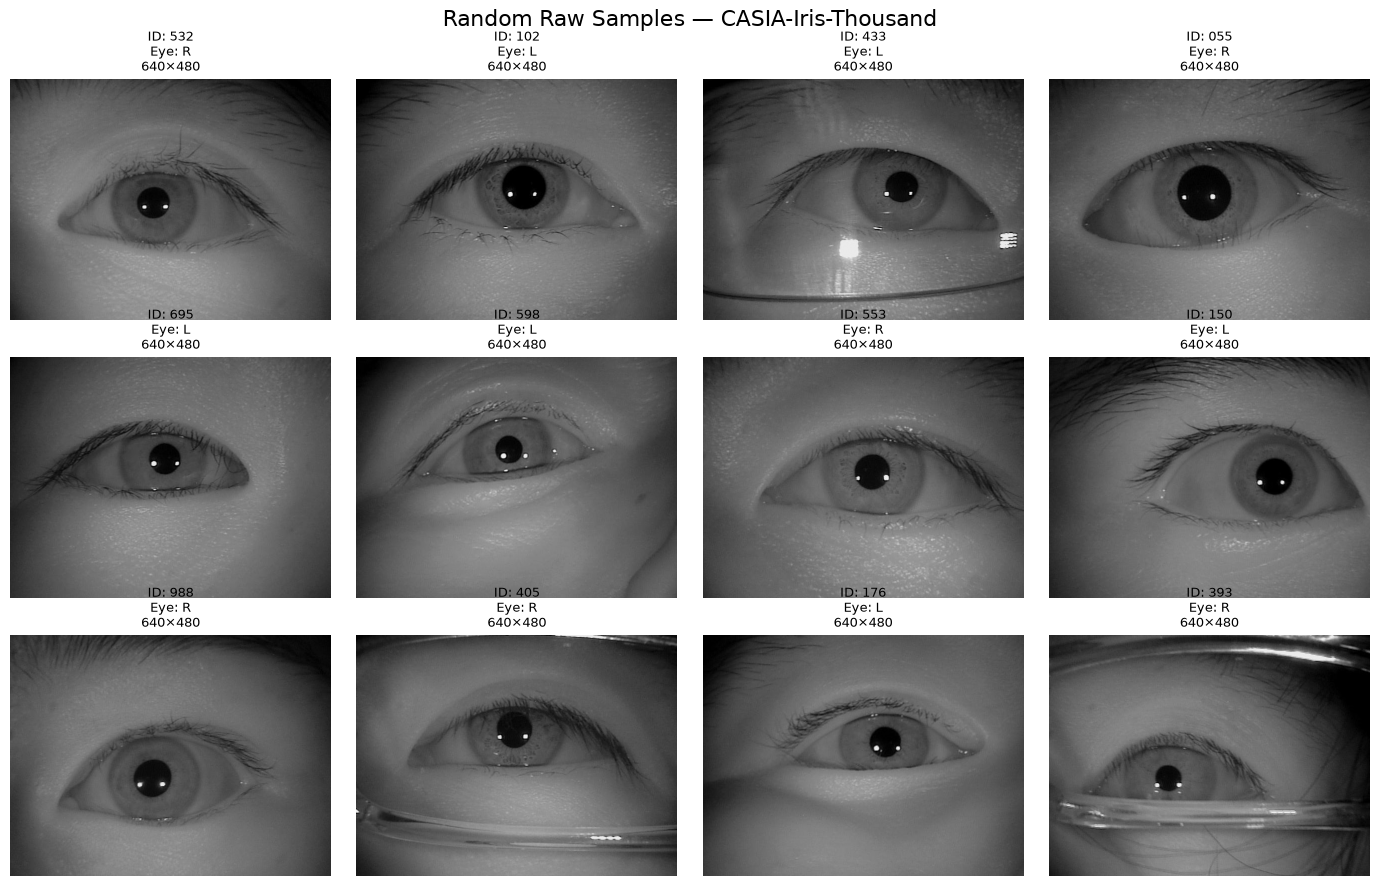

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\CASIA-Iris-Thousand_random_samples.png


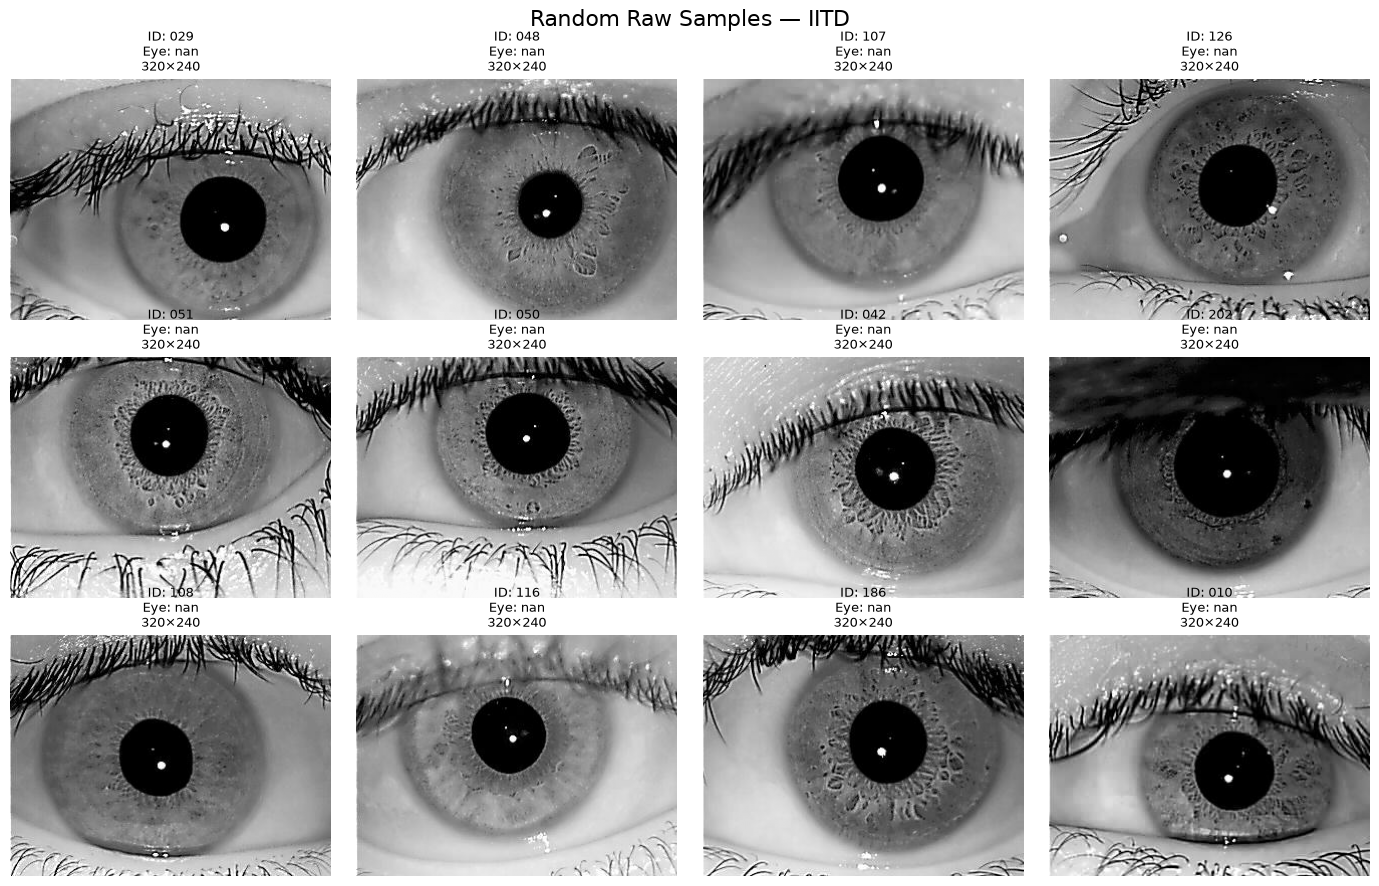

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\IITD_random_samples.png


In [17]:
def show_random_samples(df, dataset_name, n=12, seed=42):

    subset = df[df["dataset"] == dataset_name].copy()

    if len(subset) == 0:
        print(f"No images found for {dataset_name}")
        return

    n = min(n, len(subset))

    samples = subset.sample(
        n=n,
        random_state=seed
    )

    fig, axes = plt.subplots(
        3,
        4,
        figsize=(14, 9)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, samples.iterrows()):

        try:
            image = Image.open(row["full_path"]).convert("L")

            ax.imshow(image, cmap="gray")
            ax.set_title(
                f"ID: {row['identity']}\n"
                f"Eye: {row['eye']}\n"
                f"{row['width']}×{row['height']}",
                fontsize=9
            )
            ax.axis("off")

        except Exception as e:
            ax.set_title("Unable to load image")
            ax.axis("off")

    plt.suptitle(
        f"Random Raw Samples — {dataset_name}",
        fontsize=16
    )

    plt.tight_layout()

    output_path = RESULTS_DIR / f"{dataset_name}_random_samples.png"

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)


show_random_samples(
    metadata,
    "CASIA-Iris-Thousand"
)

show_random_samples(
    metadata,
    "IITD"
)

## 15. Class Imbalance Analysis

A class is considered imbalanced when different identities contain different numbers of samples.

For this project this matters because few-shot learning experiments require carefully controlled support and query sets.

We therefore calculate:

- minimum samples per identity
- maximum samples per identity
- mean
- median
- standard deviation
- coefficient of variation
- number of identities below/above selected sample thresholds

In [18]:
class_balance_stats = []

for dataset_name, df in samples_per_identity.groupby("dataset"):

    counts = df["sample_count"].values

    mean_count = np.mean(counts)

    class_balance_stats.append({
        "dataset": dataset_name,
        "min_samples": np.min(counts),
        "max_samples": np.max(counts),
        "mean_samples": np.mean(counts),
        "median_samples": np.median(counts),
        "std_samples": np.std(counts),
        "coefficient_of_variation": (
            np.std(counts) / mean_count
            if mean_count != 0
            else np.nan
        )
    })

class_balance_stats = pd.DataFrame(class_balance_stats)

display(class_balance_stats)

,dataset,min_samples,max_samples,mean_samples,median_samples,std_samples,coefficient_of_variation
0,CASIA-Iris-Thousand,20,20,20.0,20.0,0.0,0.0
1,IITD,10,10,10.0,10.0,0.0,0.0


## 16. Identity Histogram

The histogram below shows how many images are available for each identity.

For an ideal balanced dataset, most identities would have the same number of images.

Any deviation from that pattern must be understood before designing the few-shot sampling strategy.

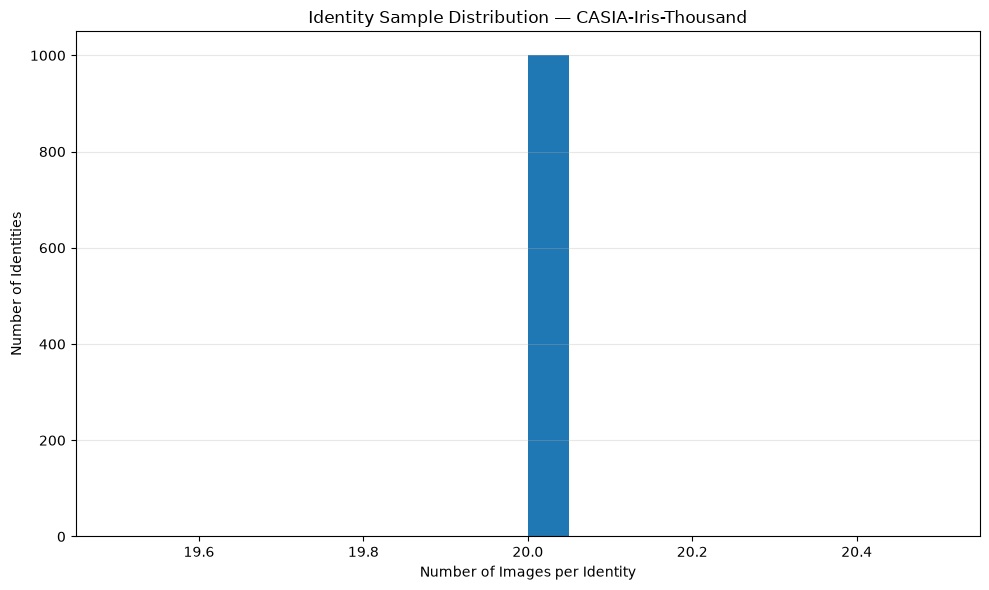

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\CASIA-Iris-Thousand_identity_histogram.png


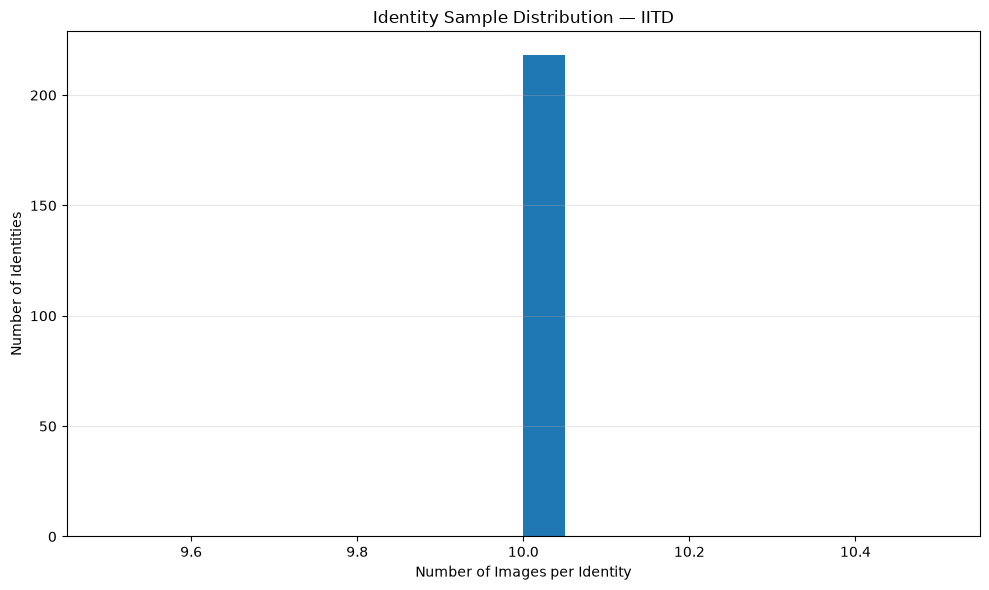

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\IITD_identity_histogram.png


In [19]:
for dataset_name, df in samples_per_identity.groupby("dataset"):

    plt.figure(figsize=(10, 6))

    plt.hist(
        df["sample_count"],
        bins=20
    )

    plt.xlabel("Number of Images per Identity")
    plt.ylabel("Number of Identities")
    plt.title(
        f"Identity Sample Distribution — {dataset_name}"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()

    output_path = RESULTS_DIR / (
        f"{dataset_name}_identity_histogram.png"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)

## 17. Dataset Distribution Visualization

We now generate a direct comparison of the two datasets in terms of:

- total number of images
- number of identities
- average samples per identity

In [20]:
dataset_summary = (
    metadata
    .groupby("dataset")
    .agg(
        total_images=("filename", "count"),
        number_of_identities=("identity", "nunique"),
        average_width=("width", "mean"),
        average_height=("height", "mean")
    )
    .reset_index()
)

dataset_summary["average_samples_per_identity"] = (
    dataset_summary["total_images"]
    / dataset_summary["number_of_identities"]
)

display(dataset_summary)

,dataset,total_images,number_of_identities,average_width,average_height,average_samples_per_identity
0,CASIA-Iris-Thousand,20000,1000,640.0,480.0,20.0
1,IITD,2180,218,320.0,240.0,10.0


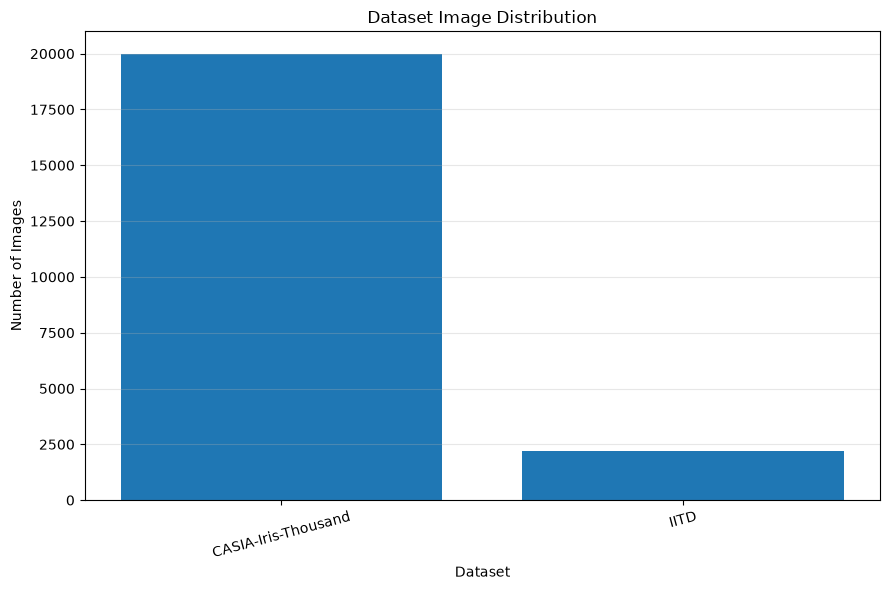

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\dataset_distribution.png


In [21]:
# Plot total number of images

plt.figure(figsize=(9, 6))

plt.bar(
    dataset_summary["dataset"],
    dataset_summary["total_images"]
)

plt.xlabel("Dataset")
plt.ylabel("Number of Images")
plt.title("Dataset Image Distribution")

plt.xticks(rotation=15)
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

distribution_path = RESULTS_DIR / "dataset_distribution.png"

plt.savefig(
    distribution_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", distribution_path)

## 18. Sensor and Acquisition Information

Sensor metadata cannot always be reconstructed from the image file itself.

Therefore, we distinguish between:

### Documented information

Information reported by the dataset creators or reliable dataset documentation.

### Empirically observed information

Information measured directly from our downloaded files, such as:

- image dimensions
- file format
- number of channels
- grayscale/RGB mode
- EXIF metadata when available

For this study we record documented acquisition information in a separate table rather than pretending that it was extracted from the pixels.

In [22]:
sensor_information = pd.DataFrame([
    {
        "dataset": "CASIA-Iris-Thousand",
        "sensor": "IKEMB-100",
        "manufacturer": "IrisKing",
        "documented_resolution": "640x480",
        "illumination": "Near-infrared / controlled iris acquisition",
        "capture_environment": "Controlled acquisition",
        "source_type": "Dataset documentation / published literature"
    },
    {
        "dataset": "IITD",
        "sensor": "JIRIS JPC1000 digital CMOS camera",
        "manufacturer": "JIRIS",
        "documented_resolution": "320x240",
        "illumination": "Near-infrared",
        "capture_environment": "Indoor controlled environment",
        "source_type": "Dataset documentation / published literature"
    }
])

display(sensor_information)

,dataset,sensor,manufacturer,documented_resolution,illumination,capture_environment,source_type
0,CASIA-Iris-Thousand,IKEMB-100,IrisKing,640x480,Near-infrared / controlled iris acquisition,Controlled acquisition,Dataset documentation / published literature
1,IITD,JIRIS JPC1000 digital CMOS camera,JIRIS,320x240,Near-infrared,Indoor controlled environment,Dataset documentation / published literature


## 19. Check EXIF Metadata

EXIF metadata is often absent from benchmark biometric datasets, but we check it explicitly.

This gives us a reproducible answer to the question:

> Does the downloaded image file itself contain sensor/capture metadata?

Do not assume that absence of EXIF means the original dataset had no sensor information. It only means the information is not embedded in the distributed image file.

In [23]:
def extract_exif(path):

    try:
        with Image.open(path) as img:

            exif_data = img.getexif()

            if not exif_data:
                return {}

            decoded = {}

            for key, value in exif_data.items():

                tag_name = ExifTags.TAGS.get(
                    key,
                    str(key)
                )

                decoded[tag_name] = value

            return decoded

    except Exception:
        return {}


# Inspect a small random sample first
sample_paths = metadata.sample(
    min(20, len(metadata)),
    random_state=RANDOM_SEED
)["full_path"].tolist()

exif_records = []

for path in sample_paths:

    exif = extract_exif(path)

    exif_records.append({
        "file": Path(path).name,
        "num_exif_fields": len(exif),
        "exif": exif
    })

exif_df = pd.DataFrame(exif_records)

display(exif_df)

,file,num_exif_fields,exif
0,06_R.bmp,0,{}
1,S5641L09.jpg,0,{}
2,S5632L05.jpg,0,{}
3,S5340R02.jpg,0,{}
4,S5876L04.jpg,0,{}
5,S5740R05.jpg,0,{}
6,S5609L08.jpg,0,{}
7,S5290L00.jpg,0,{}
8,06_R.bmp,0,{}
9,S5733L06.jpg,0,{}


## 20. Capture Condition Assessment

Some capture conditions are known from dataset documentation, while others can be empirically estimated.

We therefore distinguish:

### Known/documented

- sensor
- acquisition environment
- illumination characteristics
- nominal resolution

### Image-derived

- brightness
- contrast
- blur
- saturation
- dynamic range

These image-derived measures are preliminary quality indicators. A dedicated image-quality notebook will be created later for rigorous quality assessment.

In [24]:
def basic_image_statistics(path):

    try:
        image = np.asarray(
            Image.open(path).convert("L"),
            dtype=np.float32
        )

        return {
            "mean_intensity": image.mean(),
            "std_intensity": image.std(),
            "min_intensity": image.min(),
            "max_intensity": image.max()
        }

    except Exception:
        return {
            "mean_intensity": np.nan,
            "std_intensity": np.nan,
            "min_intensity": np.nan,
            "max_intensity": np.nan
        }


# Use a manageable sample for initial exploration
stats_sample = metadata.sample(
    min(1000, len(metadata)),
    random_state=RANDOM_SEED
).copy()

image_stats = stats_sample["full_path"].apply(
    lambda x: pd.Series(
        basic_image_statistics(x)
    )
)

stats_sample = pd.concat(
    [
        stats_sample.reset_index(drop=True),
        image_stats.reset_index(drop=True)
    ],
    axis=1
)

display(
    stats_sample[
        [
            "dataset",
            "filename",
            "mean_intensity",
            "std_intensity",
            "min_intensity",
            "max_intensity"
        ]
    ].head()
)

,dataset,filename,mean_intensity,std_intensity,min_intensity,max_intensity
0,IITD,06_R.bmp,119.595940,68.572670,0.0,255.0
1,CASIA-Iris-Thousand,S5641L09.jpg,87.454872,22.265911,0.0,255.0
2,CASIA-Iris-Thousand,S5632L05.jpg,88.424561,38.105167,0.0,255.0
3,CASIA-Iris-Thousand,S5340R02.jpg,91.379951,34.689190,0.0,253.0
4,CASIA-Iris-Thousand,S5876L04.jpg,92.083427,34.307438,0.0,255.0


## 21. Dataset-Level Intensity Statistics

We summarize basic illumination characteristics.

These statistics are not a replacement for the dedicated image-quality analysis that will be performed later.

In [25]:
capture_condition_summary = (
    stats_sample
    .groupby("dataset")
    [
        [
            "mean_intensity",
            "std_intensity",
            "min_intensity",
            "max_intensity"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
)

display(capture_condition_summary)

mean_intensity                                    \
                              mean        std        min         max   
dataset                                                                
CASIA-Iris-Thousand      89.615189   5.149096  75.644310  140.305496   
IITD                    119.506248  14.384302  74.960068  154.752136   

                    std_intensity                                  \
                             mean       std        min        max   
dataset                                                             
CASIA-Iris-Thousand     32.575569  4.978545  21.712524  53.272339   
IITD                    64.468002  6.106866  47.846481  81.878609   

                    min_intensity                max_intensity            \
                             mean  std  min  max          mean       std   
dataset                                                                    
CASIA-Iris-Thousand           0.0  0.0  0.0  0.0    254.572861  1.089522   
IITD                          0.0  0.0  0.0  0.0    255.000000  0.000000   

                                   
                       min    max  
dataset                            
CASIA-Iris-Thousand  246.0  255.0  
IITD                 255.0  255.0

## 22. Create Final Dataset Statistics Table

The final table combines the major dataset-level statistics generated in this notebook.

This table is intended for:

- later experiments
- research documentation
- paper tables
- dataset comparison
- reproducibility

In [26]:
final_statistics = []

for dataset_name, df in metadata.groupby("dataset"):

    valid_identities = df.dropna(subset=["identity"])

    samples_by_identity = (
        valid_identities
        .groupby("identity")
        .size()
    )

    final_statistics.append({
        "dataset": dataset_name,

        "total_images": len(df),

        "number_of_identities": (
            valid_identities["identity"].nunique()
        ),

        "min_samples_per_identity": (
            samples_by_identity.min()
            if len(samples_by_identity) else np.nan
        ),

        "max_samples_per_identity": (
            samples_by_identity.max()
            if len(samples_by_identity) else np.nan
        ),

        "mean_samples_per_identity": (
            samples_by_identity.mean()
            if len(samples_by_identity) else np.nan
        ),

        "median_samples_per_identity": (
            samples_by_identity.median()
            if len(samples_by_identity) else np.nan
        ),

        "std_samples_per_identity": (
            samples_by_identity.std()
            if len(samples_by_identity) else np.nan
        ),

        "mean_width": df["width"].mean(),
        "mean_height": df["height"].mean(),

        "unique_resolutions": (
    ", ".join(
        (
            df["width"].astype(str)
            + "x"
            + df["height"].astype(str)
        )
        .unique()
        .tolist()
    )
),

        "left_eye_images": (
            (df["eye"] == "L").sum()
        ),

        "right_eye_images": (
            (df["eye"] == "R").sum()
        ),

        "unknown_eye_images": (
            (~df["eye"].isin(["L", "R"])).sum()
        )
    })

final_statistics = pd.DataFrame(final_statistics)

display(final_statistics)

,dataset,total_images,number_of_identities,min_samples_per_identity,max_samples_per_identity,mean_samples_per_identity,median_samples_per_identity,std_samples_per_identity,mean_width,mean_height,unique_resolutions,left_eye_images,right_eye_images,unknown_eye_images
0,CASIA-Iris-Thousand,20000,1000,20,20,20.0,20.0,0.0,640.0,480.0,640x480,10000,10000,0
1,IITD,2180,218,10,10,10.0,10.0,0.0,320.0,240.0,320x240,0,0,2180


## 23. Save Dataset Statistics

The requested output file is:

`dataset_statistics.csv`

It is saved inside:

`results/dataset_exploration/`

In [27]:
statistics_path = RESULTS_DIR / "dataset_statistics.csv"

final_statistics.to_csv(
    statistics_path,
    index=False
)

print("Dataset statistics saved to:")
print(statistics_path)

Dataset statistics saved to:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\dataset_statistics.csv


## 24. Save Complete Image Metadata

In addition to the requested summary statistics, we save the complete image-level metadata table.

This file will be useful in later notebooks for:

- train/validation/test splitting
- few-shot sampling
- identity balancing
- quality analysis
- segmentation
- normalization

In [28]:
metadata_path = RESULTS_DIR / "image_metadata.csv"

metadata.to_csv(
    metadata_path,
    index=False
)

print("Complete image metadata saved to:")
print(metadata_path)

Complete image metadata saved to:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\dataset_exploration\image_metadata.csv


## 25. Final Output Verification

The notebook should produce at least the following requested files:

- dataset_statistics.csv
- dataset_distribution.png

Additionally, identity histograms and random sample visualizations are generated for each dataset.

In [29]:
print("Generated files:")
print("-" * 60)

for file in sorted(RESULTS_DIR.iterdir()):
    if file.is_file():
        print(f"{file.name:45s} {file.stat().st_size / 1024:.2f} KB")

Generated files:
------------------------------------------------------------
CASIA-Iris-Thousand_identity_histogram.png    53.71 KB
CASIA-Iris-Thousand_random_samples.png        2252.05 KB
dataset_distribution.png                      53.08 KB
dataset_statistics.csv                        0.41 KB
IITD_identity_histogram.png                   46.86 KB
IITD_random_samples.png                       2708.32 KB
image_metadata.csv                            5432.74 KB


# Conclusion

This notebook established the raw-data baseline for the project.

The following information has been investigated:

- dataset size
- identity count
- samples per identity
- image resolution
- left/right distribution
- class balance
- random image examples
- sensor information
- acquisition conditions
- image-level metadata

No preprocessing has been performed.

### Important research decision

The next stage should not immediately train a neural network.

Before training anything, we must first perform:

**raw image quality analysis → segmentation → iris normalization → quality filtering → controlled few-shot split creation.**

Those stages determine whether the data entering the generative model is valid and whether our later few-shot experiments are free from data leakage.